In [1]:
import warnings
from collections import defaultdict

import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr, pearsonr, linregress
from Bio.Data.IUPACData import protein_letters_1to3
import adjustText
from sankeyflow import Sankey
from seaborn import color_palette
from scipy.stats import entropy, gaussian_kde
from tqdm.auto import tqdm
import logomaker
from Bio.SeqIO.FastaIO import FastaIterator
import sys

# Ensure working directory is analysis/ so relative paths match analysis.ipynb
if os.path.basename(os.getcwd()) != "analysis" and os.path.isdir("analysis"):
    os.chdir("analysis")

sys.path.append("../src/")
os.makedirs("figures", exist_ok=True)
from satseq_analysis import (
    make_fitness_barplot,
    weighted_std,
    weighted_avg,
    shannon_diversity_index,
    summarize_data,
    mSTING,
    test_residues,
    make_fitness_heatmap,
    make_fitness_df_matrix,
)
import matplotlib as mpl
import matplotlib.colors as mcolors
import functools

# Register Archivo SemiCondensed fonts from local directory
_font_dir = os.path.join(os.getcwd(), "Archivo", "static")
for _font_file in glob.glob(os.path.join(_font_dir, "*.ttf")):
    mpl.font_manager.fontManager.addfont(_font_file)

plt.rcParams.update({
    "figure.facecolor":  (1.0, 1.0, 1.0, 1.0),  # white with alpha = 100%
    "axes.facecolor":    (1.0, 1.0, 1.0, 1.0),
    "savefig.facecolor": (1.0, 1.0, 1.0, 1.0),
    "font.size": 12,
    "font.family": "Archivo SemiCondensed",
})

# Function to calculate density
def calculate_density(x, y):
    xy = np.vstack([x, y])
    z = gaussian_kde(xy)(xy)
    return z

def density_scatter(x, y, **kwargs):
    ax = plt.gca()
    nan_mask = np.isnan(x) | np.isnan(y)
    x = x[~nan_mask]
    y = y[~nan_mask]
    z = calculate_density(x, y)
    ax.scatter(x, y, c=z, s=20, cmap='binary_r')
    return ax

def fix_nans(df):
    max_error = np.nanmax(df['standard_error'].values)
    df['standard_error'] = df['standard_error'].fillna({'standard_error': max_error * 1.1})
    df['position'] = df['position'].astype(str).str.strip()
    df['variant'] = df['variant'].str.strip()
    # Filter anything that starts with a stop codon
    df = df[~df['variant'].str.startswith("_")]
    return df.fillna(0.0)

# List of controls
controls = [
    "V146L", "N153S", "V154M", "S161A", "I229A", "Y239S", "N241A", "S365A", "I229A", "RRAA", "RRDD", "ΔCTT", "ΔUPR", "REF", "STOP"
]

# Compatibility patch for logomaker with newer matplotlib versions
from matplotlib import path as _mpl_path
_orig_Path_init = _mpl_path.Path.__init__
def _patched_Path_init(self, vertices, codes=None, _interpolation_steps=1, closed=False, readonly=False):
    if isinstance(codes, list):
        codes = np.asarray(codes, dtype=np.uint8)
    _orig_Path_init(self, vertices, codes, _interpolation_steps, closed, readonly)
_mpl_path.Path.__init__ = _patched_Path_init

C:\Users\Austin\PycharmProjects\SatSeq-Quantification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 4T1 Primary vs Met & EO771 Initial vs Tail Vein: Pro-Metastatic Variant Ranking & Correlation Analysis
**Target Variant Positions:** `175, 181, 198, 205, 209, 213` (`Q175`, `F181`, `Y198`, `C205`, `D209`, `V213` in mSTING)

This notebook follows the conventions and plotting utilities of `analysis.ipynb` to:
1. Load and inspect **4T1 Mammary Fat Pad Primary vs Met** and **EO771 Initial vs Tail Vein** bootstrap fitness results.
2. Rank the top pro-metastatic variants from **4T1 Primary vs Met** across positions `175, 181, 198, 205, 209, 213` (both at the individual amino-acid substitution level and collapsed position level, with ANOVA/t-test FDR statistics).
3. Evaluate the correlation (Pearson $r$ and Spearman $\rho$) between **4T1 Primary vs Met** and **EO771 Initial vs Tail Vein** across the target positions and library-wide.

In [2]:
# Load conservation, TCGA lollipop, and domain tracks (matching analysis.ipynb)
alignment = "STING_Alignment.fa"
data = dict()
hsapien_txid = "9606_0"
mmusculus_txid = "10090_0"
with open(alignment) as f:
    for record in FastaIterator(f):
        txid = record.id.split(":")[0]
        if txid in data:
            txid += "_1"
        data[txid] = str(record.seq)

mouse_gap_positions = [i for i, aa in enumerate(data[mmusculus_txid]) if aa == "-"]
for txid, sequence in list(data.items()):
    data[txid] = "".join([aa for i, aa in enumerate(sequence) if i not in mouse_gap_positions]).replace("-", " ")

logo_df = dict()
for sequence in data.values():
    for aa in set(sequence):
        if aa not in logo_df:
            logo_df[aa] = np.zeros(len(sequence))

for i, sequence in enumerate(data.values()):
    for j, aa in enumerate(sequence):
        logo_df[aa][j] += 1
logo_df = pd.DataFrame(logo_df)
logo_df.index = [f"{i+1}" for i, aa in enumerate(data[mmusculus_txid])]
orig_logo_df = logo_df.div(logo_df.sum(axis=1), axis=0)

bits = orig_logo_df.copy()
for col in list(bits.columns):
    bits[col] = bits[col].map(lambda x: x * np.log2(x) if x > 0 else 0)
bits = -bits.sum(axis=1) / np.log2(20)
logo_df = orig_logo_df.mul(bits, axis=0)

to_highlight = controls

for control in controls:
    try:
        num = int(control[1:-1])
        values = logo_df.loc[str(num)].values.flatten()
        orig_values = orig_logo_df.loc[str(num)].values.flatten()
    except Exception:
        values = np.zeros(logo_df.shape[1])
        orig_values = np.zeros(logo_df.shape[1])
    logo_df.loc[control] = values
    orig_logo_df.loc[control] = orig_values

def make_logo(ax, positions: list[str] = None, include_conservation=False, logo_df=logo_df, orig_logo_df=orig_logo_df, annotate_positions: list[str] = None):
    logo_df = logo_df.copy()
    orig_logo_df = orig_logo_df.copy()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if positions is not None:
            new_positions = []
            for position in positions:
                try:
                    position_sub = position[1:-1]
                    position_i = str(int(position_sub))
                    if position_i not in logo_df.index.values and position.endswith("X"):
                        logo_df.loc[position_i] = 0
                        orig_logo_df.loc[position_i] = 0
                        new_positions.append(position_i)
                    elif position not in logo_df.index.values and not position.endswith('X'):
                        logo_df.loc[position] = logo_df.loc[position_i]
                        orig_logo_df.loc[position] = orig_logo_df.loc[position_i]
                        new_positions.append(position)
                    else:
                        if position in logo_df.index.values:
                            new_positions.append(position)
                        elif position_i in logo_df.index.values:
                            new_positions.append(position_i)
                        else:
                            raise ValueError(f"Position {position_i} not in logo df")
                except Exception:
                    if position not in logo_df.index.values:
                        logo_df.loc[position] = 0
                        orig_logo_df.loc[position] = 0
                    new_positions.append(position)
            rearranged_logo_df = logo_df.loc[new_positions]
            rearranged_original_logo_df = orig_logo_df.loc[new_positions]
        else:
            rearranged_logo_df = logo_df
            rearranged_original_logo_df = orig_logo_df

        logo_plt = logomaker.Logo(
            rearranged_logo_df.reset_index(drop=True, inplace=False),
            stack_order='big_on_top',
            color_scheme={aa: 'black' for aa in rearranged_logo_df.columns},
            ax=ax
        )
        logo_plt.style_spines(visible=False)
        logo_plt.ax.set_ylabel("Frequency Index", labelpad=-1)
        logo_plt.ax.yaxis.set_ticks_position('none')
        logo_plt.ax.yaxis.set_tick_params(size=0)
        logo_plt.ax.xaxis.grid(False)
        logo_plt.ax.yaxis.grid(False)
        logo_plt.ax.spines['left'].set_visible(True)
        logo_plt.ax.xaxis.set_ticks_position('none')
        logo_plt.ax.xaxis.set_tick_params(size=0)
        plt.setp(ax.get_xticklabels(), visible=False)

        if annotate_positions:
            annotation_mask = rearranged_logo_df.index.isin(annotate_positions)
            for i, mask in enumerate(annotation_mask):
                ax.text(i, -.01, '*' if mask else ' ', ha='center', va='top')
        return logo_plt

lollipop_df = pd.read_csv("human_STING_cancer_variants.csv")
lollipop_df['ref'] = lollipop_df['variant'].str[0]
lollipop_df['alt'] = lollipop_df['variant'].str[-1]
lollipop_df['position'] = lollipop_df['variant'].str[1:-1].astype(int)
lollipop_df = lollipop_df[lollipop_df['position'] != 108]
lollipop_df['position'] = lollipop_df['position'].apply(lambda x: x - 1 if x > 108 else x).astype(str)
lollipop_df['variant'] = lollipop_df['ref'] + lollipop_df['position'] + lollipop_df['alt']
tcga_variants = lollipop_df.variant.unique().tolist()
lollipop_df = lollipop_df.groupby('position').size().reset_index(name='count')

def make_lollipop(ax, positions: list[str] = None):
    new_df = lollipop_df.copy()
    if positions is not None:
        rows = []
        for position in positions:
            try:
                position_i = str(int(position[1:-1]))
                if position_i in lollipop_df['position'].values:
                    count = lollipop_df[lollipop_df['position'] == position_i]['count'].values[0]
                    rows.append({'position': position_i, 'count': count})
                else:
                    rows.append({'position': position_i, 'count': 0})
            except Exception:
                rows.append({'position': str(position), 'count': 0})
        new_df = pd.DataFrame(rows)
    new_df['index'] = np.arange(len(new_df))
    new_df = new_df[new_df['count'] > 0]
    if not new_df.empty:
        markerline, stemlines, baseline = ax.stem(new_df['index'], new_df['count'], markerfmt='o', basefmt=' ', linefmt='black')
        stemlines.set_linewidth(5)
        markerline.set_markeredgewidth(6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.invert_yaxis()
    ax.xaxis.grid(False)
    ax.yaxis.grid(False)
    ax.set_ylabel("# Mutated")
    plt.setp(ax.get_xticklabels(), visible=False)
    return ax

conservation = pd.read_csv("conserved_residues.csv")
conservation = conservation[conservation['mouse STING'] != "'X'"]
conservation['color'] = conservation['Conserved'].apply(lambda x: 'black' if x == 1 else 'white')
conservation['mouse STING'] = conservation['mouse STING'].str.replace("'", "")
conservation['mouse pos int'] = conservation['mouse STING'].str.extract(r'(\d+)').fillna("0").astype(int)
conservation_df = conservation

position2position_names = defaultdict(list)
for _, row in conservation.iterrows():
    position = row['mouse STING']
    position_int = row['mouse pos int']
    position2position_names[position_int].append(position)
    for aa in protein_letters_1to3.keys():
        position2position_names[position_int].append(position[:-1] + aa)

domain2color = defaultdict(lambda: np.array([255, 255, 255]) / 255)
for start, end in [(18, 35), (45, 70), (92, 107), (116, 134)]:
    for i in range(start, end):
        domain2color[i] = np.array([33, 143, 155]) / 255
        for pos in position2position_names[i]:
            domain2color[pos] = np.array([33, 143, 155]) / 255
for i in range(152, 340):  # CBD
    domain2color[i] = np.array([244, 169, 47]) / 255
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([244, 169, 47]) / 255
for i in range(339, 379):  # CTT
    domain2color[i] = np.array([218, 59, 37]) / 255
    for pos in position2position_names[i]:
        domain2color[pos] = np.array([218, 59, 37]) / 255


## 1. Load 4T1 Primary vs Met and EO771 Initial vs Tail Vein Results

In [3]:
experiments = {
    "4T1_Mammary_Fat_Pad_Primary_vs_Met": fix_nans(
        pd.read_csv("../results/4T1_Mammary_Fat_Pad_Primary_vs_Met/4T1_Mammary_Fat_Pad_Primary_vs_Met_boot.csv")
    ),
    "EO771_Initial_vs_Tail_Vein": fix_nans(
        pd.read_csv("../results/EO771_Initial_vs_Tail_Vein/EO771_Initial_vs_Tail_Vein_boot.csv")
    ),
}

target_positions_int = [175, 181, 198, 205, 209, 213]
target_positions = [str(p) for p in target_positions_int]
target_wt_labels = [f"{mSTING[p - 1]}{p}X" for p in target_positions_int]

for name, df_exp in experiments.items():
    n_mice = df_exp["experiment"].nunique()
    n_vars = df_exp["variant"].nunique()
    n_target_vars = df_exp[df_exp["position"].isin(target_positions)]["variant"].nunique()
    print(f"{name}: {len(df_exp):,} rows | {n_mice} mice/replicates | {n_vars:,} total unique variants | {n_target_vars} variants in positions {target_positions_int}")


4T1_Mammary_Fat_Pad_Primary_vs_Met: 89,504 rows | 30 mice/replicates | 5,798 total unique variants | 31 variants in positions [175, 181, 198, 205, 209, 213]
EO771_Initial_vs_Tail_Vein: 35,740 rows | 10 mice/replicates | 6,074 total unique variants | 60 variants in positions [175, 181, 198, 205, 209, 213]


C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\3199334974.py:3: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  pd.read_csv("../results/4T1_Mammary_Fat_Pad_Primary_vs_Met/4T1_Mammary_Fat_Pad_Primary_vs_Met_boot.csv")


## 2. Rank Top Pro-Metastatic Variants from 4T1 Primary vs Met (Positions 175, 181, 198, 205, 209, 213)
We summarize `4T1_Mammary_Fat_Pad_Primary_vs_Met` using `summarize_data(..., keep_variants_independent=True)` (which computes the median across mice for each amino-acid substitution, plus SEM and read counts) and combine it with per-residue statistical testing from `test_residues` (one-sample t-test against WT reference fitness = 0 with BH-FDR across residues, and post-hoc t-test against other substitutions at the same position).

We also provide the collapsed position-level ranking (`keep_variants_independent=False`).

In [4]:
def compute_residue_statistics(total_output: pd.DataFrame) -> pd.DataFrame:
    """Run make_fitness_df_matrix and test_residues (both vs other residues and vs WT=0) as in analysis.ipynb."""
    fitness_matrix, residues, exps = make_fitness_df_matrix(total_output)
    fitness_test_df = test_residues(fitness_matrix, residues, compare_to_ref=False)  # Outlier residue test
    wt_fitness_test_df = test_residues(fitness_matrix, residues, compare_to_ref=True)  # Difference from WT (0)
    fitness_test_df = pd.merge(fitness_test_df, wt_fitness_test_df, on=['position', 'residue', 'observed_fitness'])
    ref_residue_df = pd.DataFrame({
        'position': [i + 1 for i in range(len(mSTING))],
        'ref': list(mSTING),
    })
    fitness_test_df = fitness_test_df.rename(columns={'residue': 'alt'})
    fitness_test_df = pd.merge(fitness_test_df, ref_residue_df, on='position', how='left')
    fitness_test_df['variant'] = fitness_test_df['ref'] + fitness_test_df['position'].astype(str) + fitness_test_df['alt']
    fitness_test_df = fitness_test_df[fitness_test_df['position'].astype(str) != fitness_test_df['variant']]
    return fitness_test_df

def add_zscore_columns(df: pd.DataFrame, val_col: str = "observed_fitness", se_col: str = "standard_error", group_col: str = None) -> pd.DataFrame:
    """Compute library-wide (or per-group) z-scored fitness and scaled SEM."""
    df = df.copy()
    if group_col is not None:
        means = df.groupby(group_col)[val_col].transform("mean")
        stds = df.groupby(group_col)[val_col].transform("std")
        df["fitness_zscore"] = (df[val_col] - means) / stds
        if se_col in df.columns:
            df["se_zscore"] = df[se_col] / stds
    else:
        mean_val = df[val_col].mean()
        std_val = df[val_col].std()
        df["fitness_zscore"] = (df[val_col] - mean_val) / std_val
        if se_col in df.columns:
            df["se_zscore"] = df[se_col] / std_val
    return df

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    # Variant-level summaries (unweighted median across mice, matching analysis.ipynb)
    by_exp_4t1_var, by_pos_4t1_var = summarize_data(
        experiments["4T1_Mammary_Fat_Pad_Primary_vs_Met"].copy(),
        keep_variants_independent=True,
        infill_positions=[],
        weighted=False,
    )
    by_exp_eo771_var, by_pos_eo771_var = summarize_data(
        experiments["EO771_Initial_vs_Tail_Vein"].copy(),
        keep_variants_independent=True,
        infill_positions=[],
        weighted=False,
    )

    # Collapsed position-level summaries
    by_exp_4t1_pos, by_pos_4t1_pos = summarize_data(
        experiments["4T1_Mammary_Fat_Pad_Primary_vs_Met"].copy(),
        keep_variants_independent=False,
        infill_positions=[],
        weighted=False,
    )
    by_exp_eo771_pos, by_pos_eo771_pos = summarize_data(
        experiments["EO771_Initial_vs_Tail_Vein"].copy(),
        keep_variants_independent=False,
        infill_positions=[],
        weighted=False,
    )

    # Residue-level ANOVA & t-test statistics
    stats_4t1 = compute_residue_statistics(experiments["4T1_Mammary_Fat_Pad_Primary_vs_Met"].copy())
    stats_eo771 = compute_residue_statistics(experiments["EO771_Initial_vs_Tail_Vein"].copy())

# Z-score fitness values across the full library for each experiment (and per-mouse for mouse-level distributions)
by_pos_4t1_var = add_zscore_columns(by_pos_4t1_var)
by_pos_eo771_var = add_zscore_columns(by_pos_eo771_var)
by_pos_4t1_pos = add_zscore_columns(by_pos_4t1_pos)
by_pos_eo771_pos = add_zscore_columns(by_pos_eo771_pos)
by_exp_4t1_var = add_zscore_columns(by_exp_4t1_var, group_col="mouse")
by_exp_eo771_var = add_zscore_columns(by_exp_eo771_var, group_col="mouse")
stats_4t1 = add_zscore_columns(stats_4t1)
stats_eo771 = add_zscore_columns(stats_eo771)

# Filter 4T1 variants to target positions: 175, 181, 198, 205, 209, 213
ranked_4t1 = by_pos_4t1_var[by_pos_4t1_var["position"].isin(target_positions)].copy()
ranked_4t1 = pd.merge(
    ranked_4t1,
    stats_4t1[["variant", "p_value", "fdr", "t_pvalue", "t_fdr", "anova_pvalue"]],
    on="variant",
    how="left",
)

# Attach EO771 Initial vs Tail Vein fitness & z-scores for each variant
eo771_lookup = pd.merge(
    by_pos_eo771_var[by_pos_eo771_var["position"].isin(target_positions)][
        ["variant", "observed_fitness", "standard_error", "fitness_zscore", "se_zscore", "n", "count", "initial_count"]
    ],
    stats_eo771[["variant", "p_value", "fdr", "t_fdr"]],
    on="variant",
    how="left",
).rename(columns={
    "observed_fitness": "eo771_fitness",
    "standard_error": "eo771_se",
    "fitness_zscore": "eo771_fitness_zscore",
    "se_zscore": "eo771_se_zscore",
    "n": "eo771_n_mice",
    "count": "eo771_count",
    "initial_count": "eo771_initial_count",
    "p_value": "eo771_p_value",
    "fdr": "eo771_fdr",
    "t_fdr": "eo771_t_fdr",
})

ranked_4t1 = pd.merge(ranked_4t1, eo771_lookup, on="variant", how="left")
ranked_4t1 = ranked_4t1.sort_values("fitness_zscore", ascending=False).reset_index(drop=True)
ranked_4t1["rank_all"] = np.arange(1, len(ranked_4t1) + 1)

# Separate specific amino-acid substitutions from positional-only ('X') barcodes
ranked_4t1_substitutions = ranked_4t1[ranked_4t1["residue"] != "X"].copy().reset_index(drop=True)
ranked_4t1_substitutions["rank"] = np.arange(1, len(ranked_4t1_substitutions) + 1)

os.makedirs("figures/pro_metastatic_175_213", exist_ok=True)
ranked_4t1.to_excel("figures/pro_metastatic_175_213/4T1_Primary_vs_Met_ranked_variants_positions_175_181_198_205_209_213.xlsx", index=False)
ranked_4t1.to_csv("figures/pro_metastatic_175_213/4T1_Primary_vs_Met_ranked_variants_positions_175_181_198_205_209_213.csv", index=False)

display_cols = [
    "rank", "position", "variant", "fitness_zscore", "se_zscore", "observed_fitness", "standard_error", "n",
    "count", "initial_count", "p_value", "fdr", "t_fdr",
    "eo771_fitness_zscore", "eo771_se_zscore", "eo771_fitness", "eo771_se", "eo771_n_mice"
]
print("=== All Ranked Pro-Metastatic Amino-Acid Substitutions in 4T1 Primary vs Met (Positions 175, 181, 198, 205, 209, 213) ===")
display(ranked_4t1_substitutions[display_cols])


=== All Ranked Pro-Metastatic Amino-Acid Substitutions in 4T1 Primary vs Met (Positions 175, 181, 198, 205, 209, 213) ===


,rank,position,variant,fitness_zscore,se_zscore,observed_fitness,standard_error,n,count,initial_count,p_value,fdr,t_fdr,eo771_fitness_zscore,eo771_se_zscore,eo771_fitness,eo771_se,eo771_n_mice
0,1,181,F181V,4.483312,0.252120,0.608361,0.033480,2,214,33.0,NaN,NaN,NaN,0.497524,0.142073,-0.087002,0.010000,1.0
1,2,198,Y198K,3.973490,0.967478,0.540659,0.128477,3,289,106.0,7.334844e-02,2.272433e-01,NaN,0.118226,2.344444,-0.113700,0.165017,3.0
2,3,175,Q175D,3.712955,0.236084,0.506061,0.031351,18,3351,2302.0,2.486131e-11,2.975263e-09,0.000169,-0.638151,0.781408,-0.166938,0.055000,6.0
3,4,205,C205Y,3.675647,0.448440,0.501107,0.059551,14,1544,4007.0,1.718239e-05,3.947346e-04,0.086076,NaN,NaN,NaN,NaN,NaN
4,5,175,Q175E,3.383513,0.350651,0.462313,0.046565,20,3057,3983.0,7.789841e-08,4.335446e-06,0.120397,-0.197909,0.767376,-0.135951,0.054013,7.0
5,6,175,Q175A,3.259323,0.444955,0.445821,0.059088,12,1372,802.0,2.732041e-05,5.623633e-04,0.203016,0.845048,0.667441,-0.062542,0.046979,9.0
6,7,175,Q175W,3.194499,0.229014,0.437212,0.030412,20,2742,2370.0,1.090500e-11,1.368710e-09,0.000881,1.548174,1.112273,-0.013051,0.078289,8.0
7,8,181,F181G,3.104357,1.402923,0.425242,0.186302,2,125,34.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,9,205,C205V,3.092426,0.075304,0.423658,0.010000,1,1,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,10,181,F181E,3.058089,0.478171,0.419098,0.063499,7,501,1042.0,1.645684e-03,1.467710e-02,NaN,0.350433,0.790239,-0.097356,0.055622,8.0


In [5]:
# Filter to statistically significant pro-metastatic variants (n >= 3 mice, BH-FDR < 0.05 vs WT)
ranked_4t1_sig = ranked_4t1_substitutions[
    (ranked_4t1_substitutions["n"] >= 3) & (ranked_4t1_substitutions["fdr"] < 0.05)
].copy().reset_index(drop=True)
ranked_4t1_sig["sig_rank"] = np.arange(1, len(ranked_4t1_sig) + 1)

print("=== Statistically Significant Pro-Metastatic Variants in 4T1 Primary vs Met (n >= 3 mice, FDR < 0.05) ===")
display(ranked_4t1_sig[[
    "sig_rank", "rank", "position", "variant",
    "fitness_zscore", "se_zscore", "observed_fitness", "standard_error", "n", "fdr", "t_fdr",
    "eo771_fitness_zscore", "eo771_se_zscore", "eo771_fitness", "eo771_se", "eo771_n_mice"
]])

# Collapsed position-level ranking across the 6 positions
pos_ranking = pd.merge(
    by_pos_4t1_pos[by_pos_4t1_pos["position"].isin(target_positions)][
        ["position", "variant", "fitness_zscore", "se_zscore", "observed_fitness", "standard_error", "n", "count", "initial_count", "n_significant"]
    ],
    by_pos_eo771_pos[by_pos_eo771_pos["position"].isin(target_positions)][
        ["position", "variant", "fitness_zscore", "se_zscore", "observed_fitness", "standard_error", "n", "count", "initial_count", "n_significant"]
    ],
    on=["position", "variant"],
    suffixes=("_4T1_Primary_vs_Met", "_EO771_Initial_vs_Tail_Vein"),
).sort_values("fitness_zscore_4T1_Primary_vs_Met", ascending=False).reset_index(drop=True)
pos_ranking["pos_rank"] = np.arange(1, len(pos_ranking) + 1)

print("=== Collapsed Position-Level Ranking (4T1 Primary vs Met vs EO771 Initial vs Tail Vein) ===")
display(pos_ranking)


=== Statistically Significant Pro-Metastatic Variants in 4T1 Primary vs Met (n >= 3 mice, FDR < 0.05) ===


,sig_rank,rank,position,variant,fitness_zscore,se_zscore,observed_fitness,standard_error,n,fdr,t_fdr,eo771_fitness_zscore,eo771_se_zscore,eo771_fitness,eo771_se,eo771_n_mice
0,1,3,175,Q175D,3.712955,0.236084,0.506061,0.031351,18,2.975263e-09,0.000169,-0.638151,0.781408,-0.166938,0.055000,6.0
1,2,4,205,C205Y,3.675647,0.448440,0.501107,0.059551,14,3.947346e-04,0.086076,NaN,NaN,NaN,NaN,NaN
2,3,5,175,Q175E,3.383513,0.350651,0.462313,0.046565,20,4.335446e-06,0.120397,-0.197909,0.767376,-0.135951,0.054013,7.0
3,4,6,175,Q175A,3.259323,0.444955,0.445821,0.059088,12,5.623633e-04,0.203016,0.845048,0.667441,-0.062542,0.046979,9.0
4,5,7,175,Q175W,3.194499,0.229014,0.437212,0.030412,20,1.368710e-09,0.000881,1.548174,1.112273,-0.013051,0.078289,8.0
5,6,10,181,F181E,3.058089,0.478171,0.419098,0.063499,7,1.467710e-02,NaN,0.350433,0.790239,-0.097356,0.055622,8.0
6,7,11,175,Q175C,3.051183,0.276583,0.418181,0.036729,22,9.305166e-08,0.078858,NaN,NaN,NaN,NaN,NaN
7,8,12,209,D209Q,2.924510,0.375458,0.401359,0.049859,10,3.714458e-04,NaN,NaN,NaN,NaN,NaN,NaN
8,9,13,213,V213T,2.643179,0.506691,0.364000,0.067286,11,8.610894e-03,NaN,-0.711937,0.674632,-0.172132,0.047485,8.0
9,10,14,175,Q175N,2.610798,0.340594,0.359699,0.045229,22,1.506989e-05,0.530244,NaN,NaN,NaN,NaN,NaN


=== Collapsed Position-Level Ranking (4T1 Primary vs Met vs EO771 Initial vs Tail Vein) ===


,position,variant,fitness_zscore_4T1_Primary_vs_Met,se_zscore_4T1_Primary_vs_Met,observed_fitness_4T1_Primary_vs_Met,standard_error_4T1_Primary_vs_Met,n_4T1_Primary_vs_Met,count_4T1_Primary_vs_Met,initial_count_4T1_Primary_vs_Met,n_significant_4T1_Primary_vs_Met,fitness_zscore_EO771_Initial_vs_Tail_Vein,se_zscore_EO771_Initial_vs_Tail_Vein,observed_fitness_EO771_Initial_vs_Tail_Vein,standard_error_EO771_Initial_vs_Tail_Vein,n_EO771_Initial_vs_Tail_Vein,count_EO771_Initial_vs_Tail_Vein,initial_count_EO771_Initial_vs_Tail_Vein,n_significant_EO771_Initial_vs_Tail_Vein,pos_rank
0,198,Y198X,6.515117,1.520136,0.540659,0.128477,3,289,106.0,1.0,1.350739,1.261375,-0.084602,0.038725,10,239323,6708.0,3.0,1
1,181,F181X,5.114356,0.496509,0.422271,0.041963,9,840,1109.0,2.0,-0.633276,1.546302,-0.145512,0.047472,10,912980,21361.0,4.0,2
2,209,D209X,5.027298,0.565675,0.414914,0.047809,11,827,533.0,2.0,0.366436,1.529221,-0.114821,0.046947,9,554817,7774.0,4.0,3
3,213,V213X,4.415319,0.730457,0.363191,0.061736,12,1570,4089.0,2.0,-0.951176,0.792474,-0.155272,0.024329,10,936295,26133.0,4.0,4
4,205,C205X,3.811740,0.571691,0.312179,0.048317,22,1578,6808.0,3.0,1.734683,2.129372,-0.072815,0.065372,8,155604,1059.0,1.0,5
5,175,Q175X,2.880524,0.285262,0.233475,0.024109,30,46475,423376.0,20.0,-0.693708,0.777130,-0.147367,0.023858,10,2655133,43895.0,7.0,6


C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\2523875023.py:57: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  legend_handles = [mpatches.Patch(color=pos_palette[p], edgecolor="black", label=f"Position {p} ({mSTING[int(p)-1]}{p})") for p in target_positions]


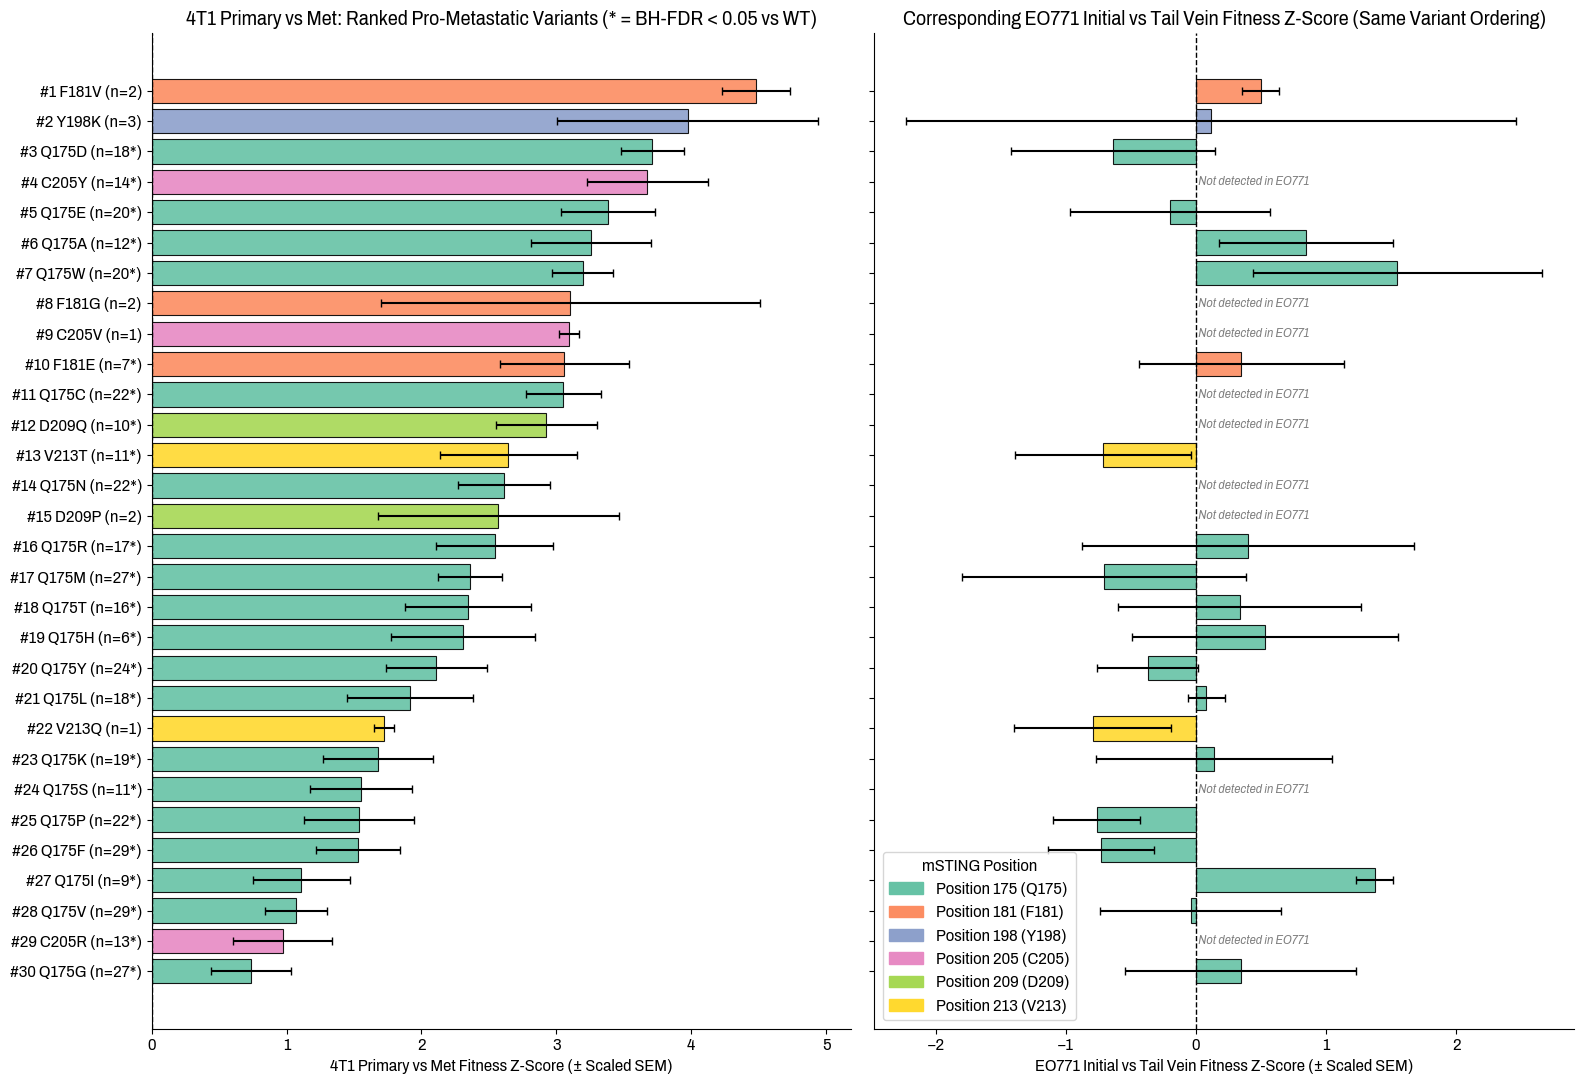

In [6]:
# Plot ranked pro-metastatic variants in 4T1 Primary vs Met alongside EO771 Initial vs Tail Vein (Z-Scored Fitness)
pos_palette = dict(zip(target_positions, sns.color_palette("Set2", len(target_positions))))

fig, axes = plt.subplots(1, 2, figsize=(16, 11), sharey=True)

plot_df = ranked_4t1_substitutions.copy()
y_pos = np.arange(len(plot_df))
bar_colors = [pos_palette[p] for p in plot_df["position"]]

# Panel A: 4T1 Primary vs Met ranked fitness Z-score
axes[0].barh(
    y_pos,
    plot_df["fitness_zscore"],
    xerr=plot_df["se_zscore"],
    color=bar_colors,
    edgecolor="black",
    linewidth=0.8,
    capsize=3,
    alpha=0.9,
)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([
    f"#{r} {v} (n={int(n)}{'*' if (not np.isnan(f) and f < 0.05) else ''})"
    for r, v, n, f in zip(plot_df["rank"], plot_df["variant"], plot_df["n"], plot_df["fdr"])
])
axes[0].invert_yaxis()
axes[0].set_xlabel("4T1 Primary vs Met Fitness Z-Score (± Scaled SEM)")
axes[0].set_title("4T1 Primary vs Met: Ranked Pro-Metastatic Variants (* = BH-FDR < 0.05 vs WT)")
axes[0].grid(False)
sns.despine(ax=axes[0])

# Panel B: Corresponding EO771 Initial vs Tail Vein fitness Z-score
eo771_vals = plot_df["eo771_fitness_zscore"].fillna(0.0).values
eo771_errs = plot_df["eo771_se_zscore"].fillna(0.0).values
has_eo771 = plot_df["eo771_fitness_zscore"].notna().values

axes[1].barh(
    y_pos[has_eo771],
    eo771_vals[has_eo771],
    xerr=eo771_errs[has_eo771],
    color=np.array(bar_colors)[has_eo771],
    edgecolor="black",
    linewidth=0.8,
    capsize=3,
    alpha=0.9,
)
for idx in y_pos[~has_eo771]:
    axes[1].text(0.0, idx, " Not detected in EO771", va="center", ha="left", fontsize=9, color="grey", style="italic")

axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("EO771 Initial vs Tail Vein Fitness Z-Score (± Scaled SEM)")
axes[1].set_title("Corresponding EO771 Initial vs Tail Vein Fitness Z-Score (Same Variant Ordering)")
axes[1].grid(False)
sns.despine(ax=axes[1])

legend_handles = [mpatches.Patch(color=pos_palette[p], edgecolor="black", label=f"Position {p} ({mSTING[int(p)-1]}{p})") for p in target_positions]
axes[1].legend(handles=legend_handles, loc="lower left", title="mSTING Position", frameon=True)

plt.tight_layout()
plt.savefig("figures/pro_metastatic_175_213/4T1_ranked_variants_vs_EO771_barplot.svg")
plt.savefig("figures/pro_metastatic_175_213/4T1_ranked_variants_vs_EO771_barplot.pdf")
plt.show()


## 3. Correlation Between 4T1 Primary vs Met and EO771 Initial vs Tail Vein
We check the correlation between **4T1 Primary vs Met** and **EO771 Initial vs Tail Vein**:
1. Across the target positions (`175, 181, 198, 205, 209, 213`) at the variant level (all shared variants, specific amino-acid substitutions excluding `X`, high-confidence variants with $\ge 3$ mice, and Position 175 substitutions).
2. Across the 6 collapsed positions (`Q175X`, `F181X`, `Y198X`, `C205X`, `D209X`, `V213X`).
3. Across all shared variants in the library using the `correlate_experiments` function from `analysis.ipynb`, highlighting our 6 positions of interest.

In [7]:
# Build correlation summary table across subsets of interest
shared_target_all = ranked_4t1[ranked_4t1["eo771_fitness"].notna()].copy()
shared_target_subs = ranked_4t1_substitutions[ranked_4t1_substitutions["eo771_fitness"].notna()].copy()
shared_target_sig = ranked_4t1_sig[ranked_4t1_sig["eo771_fitness"].notna()].copy()
shared_target_min3_both = shared_target_subs[(shared_target_subs["n"] >= 3) & (shared_target_subs["eo771_n_mice"] >= 3)].copy()
shared_pos175_subs = shared_target_subs[shared_target_subs["position"] == "175"].copy()

all_library_merged = pd.merge(
    by_pos_4t1_var,
    by_pos_eo771_var,
    on=["variant", "position", "residue", "is_control"],
    suffixes=("_4T1", "_EO771"),
    how="inner",
).dropna(subset=["observed_fitness_4T1", "observed_fitness_EO771"])

def summarize_corr(name, x, y):
    r_p, p_p = pearsonr(x, y)
    r_s, p_s = spearmanr(x, y)
    return {
        "Subset": name,
        "N": len(x),
        "Pearson_r": r_p,
        "Pearson_p": p_p,
        "Spearman_rho": r_s,
        "Spearman_p": p_s,
    }

corr_summary_df = pd.DataFrame([
    summarize_corr("Target positions (175,181,198,205,209,213) - All shared variants", shared_target_all["observed_fitness"], shared_target_all["eo771_fitness"]),
    summarize_corr("Target positions (175,181,198,205,209,213) - Specific AA substitutions (excl. X)", shared_target_subs["observed_fitness"], shared_target_subs["eo771_fitness"]),
    summarize_corr("Target positions - 4T1 FDR < 0.05 & n >= 3 mice", shared_target_sig["observed_fitness"], shared_target_sig["eo771_fitness"]),
    summarize_corr("Target positions - n >= 3 mice in BOTH 4T1 and EO771", shared_target_min3_both["observed_fitness"], shared_target_min3_both["eo771_fitness"]),
    summarize_corr("Position 175 only - Specific AA substitutions", shared_pos175_subs["observed_fitness"], shared_pos175_subs["eo771_fitness"]),
    summarize_corr("Target positions - Collapsed position-level medians (6 positions)", pos_ranking["observed_fitness_4T1_Primary_vs_Met"], pos_ranking["observed_fitness_EO771_Initial_vs_Tail_Vein"]),
    summarize_corr("Entire Library - All shared variants", all_library_merged["observed_fitness_4T1"], all_library_merged["observed_fitness_EO771"]),
])

corr_summary_df.to_excel("figures/pro_metastatic_175_213/4T1_vs_EO771_correlation_summary.xlsx", index=False)
display(corr_summary_df)


,Subset,N,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,"Target positions (175,181,198,205,209,213) - A...",22,0.115545,0.608624,0.207228,0.354786
1,"Target positions (175,181,198,205,209,213) - S...",21,0.124122,0.591925,0.209091,0.363026
2,Target positions - 4T1 FDR < 0.05 & n >= 3 mice,18,0.023300,0.926883,0.106295,0.674640
3,Target positions - n >= 3 mice in BOTH 4T1 and...,15,0.215517,0.440462,0.210714,0.450958
4,Position 175 only - Specific AA substitutions,16,0.042058,0.877095,0.085294,0.753465
5,Target positions - Collapsed position-level me...,6,0.336207,0.514691,0.257143,0.622787
6,Entire Library - All shared variants,5174,-0.041970,0.002532,-0.056946,0.000042


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.
C:\Users\Austin\PycharmProjects\SatSeq-Quantification\.venv\Lib\site-packages\adjustText\__init__.py:419: UserWarning: Glyph 961 (\N{GREEK SMALL LETTER RHO}) missing from font(s) Archivo SemiCondensed.
  ax.figure.draw_without_rendering()
C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\4289990377.py:136: UserWarning: Glyph 961 (\N{GREEK SMALL LETTER RHO}) missing from font(s) Archivo SemiCondensed.
  plt.tight_layout()
C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\4289990377.py:137: UserWarning: Glyph 961 (\N{GREEK SMALL LETTER RHO}) missing from font(s) Archivo SemiCondensed.
  plt.savefig("figures/pro_metastatic_175_213/4T1_vs_EO771_target_positions_correlation.svg")
C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\4289990377.py:138: UserWarning: Glyph 961 (\N{GREEK SMALL LETTER RHO}) missing

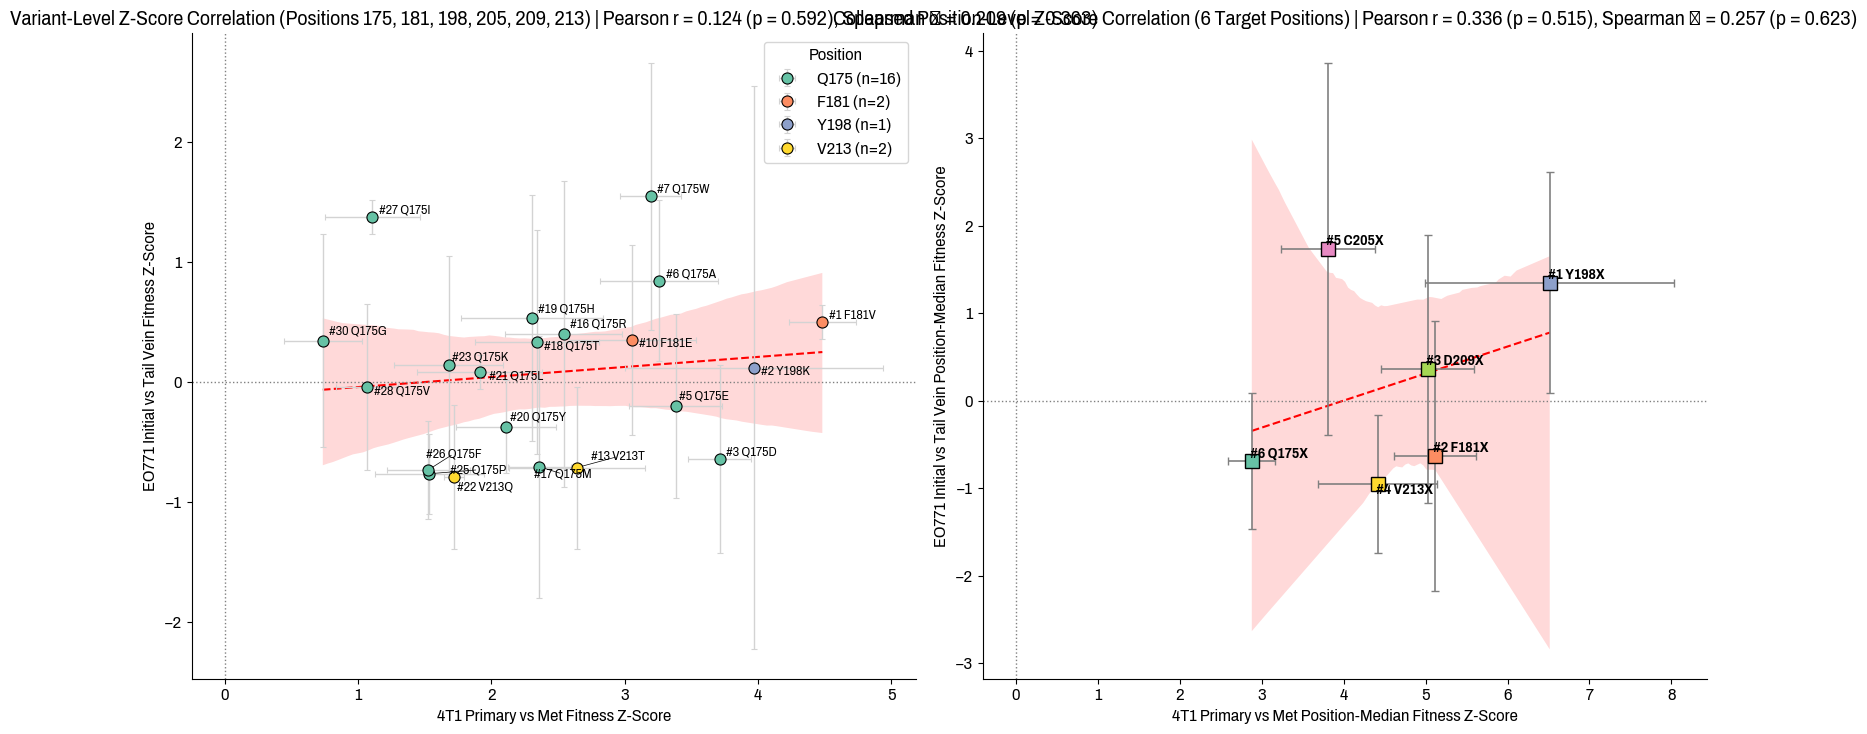

In [8]:
# Scatter / regression plots for positions 175, 181, 198, 205, 209, 213 (Z-Scored Fitness: Variant-level & Position-level)
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

# Left panel: Variant-level Z-score correlation across shared substitutions
ax = axes[0]
sns.regplot(
    data=shared_target_subs,
    x="fitness_zscore",
    y="eo771_fitness_zscore",
    scatter=False,
    ax=ax,
    color="red",
    line_kws={"linewidth": 1.5, "linestyle": "--"},
)

for pos in target_positions:
    sub = shared_target_subs[shared_target_subs["position"] == pos]
    if sub.empty:
        continue
    ax.errorbar(
        sub["fitness_zscore"],
        sub["eo771_fitness_zscore"],
        xerr=sub["se_zscore"],
        yerr=sub["eo771_se_zscore"],
        fmt="o",
        color=pos_palette[pos],
        ecolor="lightgrey",
        elinewidth=1,
        capsize=2,
        markersize=8,
        markeredgecolor="black",
        markeredgewidth=0.8,
        label=f"{mSTING[int(pos)-1]}{pos} (n={len(sub)})",
        zorder=3,
    )

texts = []
for _, row in shared_target_subs.iterrows():
    texts.append(
        ax.text(
            row["fitness_zscore"],
            row["eo771_fitness_zscore"],
            f"#{int(row['rank'])} {row['variant']}",
            fontsize=9,
            zorder=4,
        )
    )
adjustText.adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="black", lw=0.5),
    expand_points=(1.4, 1.4),
)

r_p, p_p = pearsonr(shared_target_subs["fitness_zscore"], shared_target_subs["eo771_fitness_zscore"])
r_s, p_s = spearmanr(shared_target_subs["fitness_zscore"], shared_target_subs["eo771_fitness_zscore"])
ax.axhline(0, color="grey", linestyle=":", linewidth=1)
ax.axvline(0, color="grey", linestyle=":", linewidth=1)
ax.grid(False)
sns.despine(ax=ax)
ax.set_xlabel("4T1 Primary vs Met Fitness Z-Score")
ax.set_ylabel("EO771 Initial vs Tail Vein Fitness Z-Score")
ax.set_title(
    f"Variant-Level Z-Score Correlation (Positions 175, 181, 198, 205, 209, 213) | "
    f"Pearson r = {r_p:.3f} (p = {p_p:.3f}), Spearman ρ = {r_s:.3f} (p = {p_s:.3f})"
)
ax.legend(loc="best", frameon=True, title="Position")

# Right panel: Collapsed position-level Z-score correlation across the 6 positions
ax2 = axes[1]
sns.regplot(
    data=pos_ranking,
    x="fitness_zscore_4T1_Primary_vs_Met",
    y="fitness_zscore_EO771_Initial_vs_Tail_Vein",
    scatter=False,
    ax=ax2,
    color="red",
    line_kws={"linewidth": 1.5, "linestyle": "--"},
)
for _, row in pos_ranking.iterrows():
    pos = row["position"]
    ax2.errorbar(
        row["fitness_zscore_4T1_Primary_vs_Met"],
        row["fitness_zscore_EO771_Initial_vs_Tail_Vein"],
        xerr=row["se_zscore_4T1_Primary_vs_Met"],
        yerr=row["se_zscore_EO771_Initial_vs_Tail_Vein"],
        fmt="s",
        color=pos_palette[pos],
        ecolor="grey",
        elinewidth=1.2,
        capsize=3,
        markersize=10,
        markeredgecolor="black",
        markeredgewidth=1.0,
        zorder=3,
    )

texts2 = []
for _, row in pos_ranking.iterrows():
    texts2.append(
        ax2.text(
            row["fitness_zscore_4T1_Primary_vs_Met"],
            row["fitness_zscore_EO771_Initial_vs_Tail_Vein"],
            f"#{int(row['pos_rank'])} {row['variant']}",
            fontsize=10,
            weight="bold",
            zorder=4,
        )
    )
adjustText.adjust_text(
    texts2,
    ax=ax2,
    arrowprops=dict(arrowstyle="-", color="black", lw=0.6),
    expand_points=(1.5, 1.5),
)

r_p_pos, p_p_pos = pearsonr(
    pos_ranking["fitness_zscore_4T1_Primary_vs_Met"],
    pos_ranking["fitness_zscore_EO771_Initial_vs_Tail_Vein"],
)
r_s_pos, p_s_pos = spearmanr(
    pos_ranking["fitness_zscore_4T1_Primary_vs_Met"],
    pos_ranking["fitness_zscore_EO771_Initial_vs_Tail_Vein"],
)
ax2.axhline(0, color="grey", linestyle=":", linewidth=1)
ax2.axvline(0, color="grey", linestyle=":", linewidth=1)
ax2.grid(False)
sns.despine(ax=ax2)
ax2.set_xlabel("4T1 Primary vs Met Position-Median Fitness Z-Score")
ax2.set_ylabel("EO771 Initial vs Tail Vein Position-Median Fitness Z-Score")
ax2.set_title(
    f"Collapsed Position-Level Z-Score Correlation (6 Target Positions) | "
    f"Pearson r = {r_p_pos:.3f} (p = {p_p_pos:.3f}), Spearman ρ = {r_s_pos:.3f} (p = {p_s_pos:.3f})"
)

plt.tight_layout()
plt.savefig("figures/pro_metastatic_175_213/4T1_vs_EO771_target_positions_correlation.svg")
plt.savefig("figures/pro_metastatic_175_213/4T1_vs_EO771_target_positions_correlation.pdf")
plt.show()


Library-wide Z-score correlation between 4T1_Mammary_Fat_Pad_Primary_vs_Met and EO771_Initial_vs_Tail_Vein (N=5174):
  Pearson r  = -0.0420 (p-value: 2.5319e-03)
  Spearman ρ = -0.0569 (p-value: 4.1589e-05)


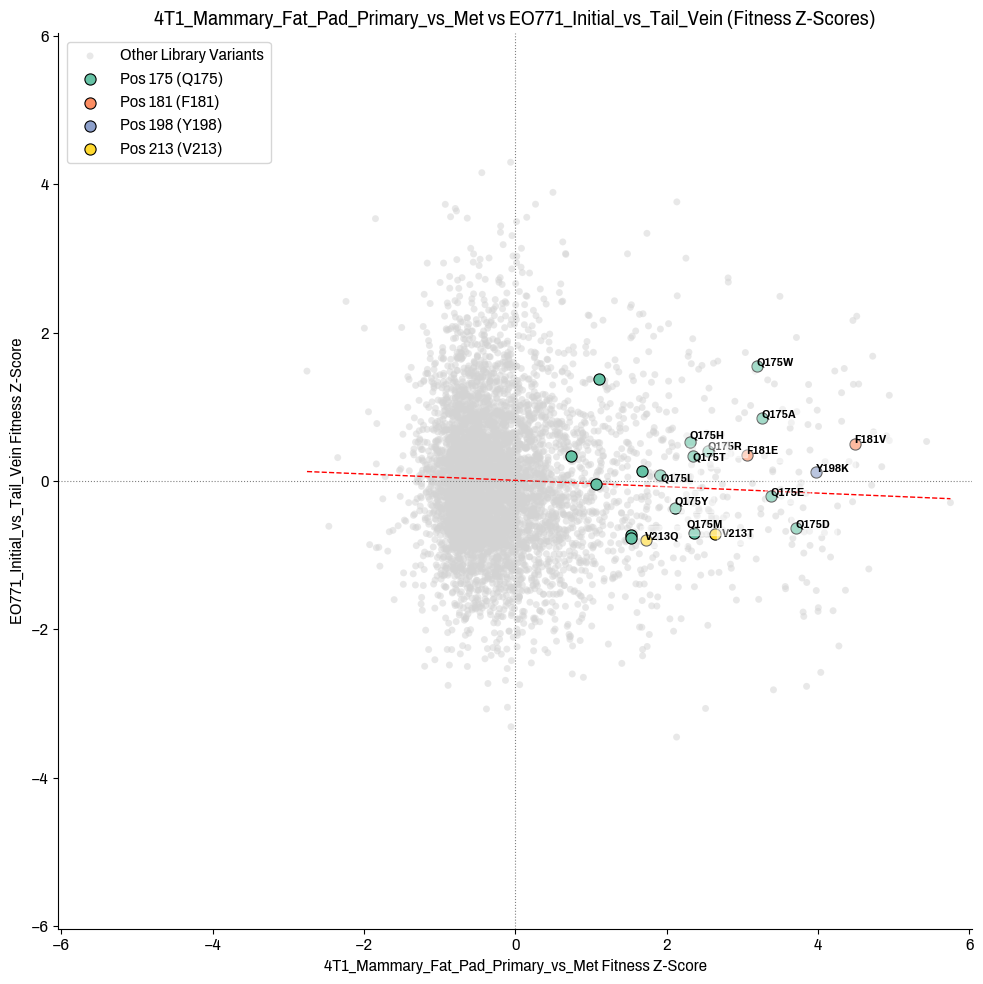

In [9]:
# Library-wide Z-scored correlation (matching correlate_experiments in analysis.ipynb) with target positions highlighted
def annotate_extreme(threshold, upper_name, neutral_name):
    def annot_fn(df, name1, name2):
        cutoff = np.quantile(
            np.concatenate([df[f'fitness_zscore_{name1}'].abs().values, df[f'fitness_zscore_{name2}'].abs().values]),
            1 - threshold,
        )
        extreme_mask = (
            ((df[f'fitness_zscore_{name1}'].abs() > cutoff) | (df[f'fitness_zscore_{name2}'].abs() > cutoff))
            & (~df[f'fitness_zscore_{name1}'].isna())
            & (~df[f'fitness_zscore_{name2}'].isna())
        )
        df['extreme_points'] = extreme_mask
        df.loc[df['extreme_points'], 'colors'] = 'red'
        return df

    return annot_fn, {upper_name: 'red', neutral_name: 'black'}

def no_annotations():
    def annot_fn(df, name1, name2):
        df['extreme_points'] = False
        return df

    return annot_fn, {'': 'black'}

def correlate_experiments(name1, name2, annot_fn, legend, show_legend=True, as_density=False, highlight_positions=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        df1 = add_zscore_columns(summarize_data(experiments[name1].copy(), keep_variants_independent=True, infill_positions=[])[1])
        df2 = add_zscore_columns(summarize_data(experiments[name2].copy(), keep_variants_independent=True, infill_positions=[])[1])

    if name1 == name2:
        name1 += " 1"
        name2 += " 2"

    df1['Name'] = name1
    df2['Name'] = name2
    joined = pd.merge(df1, df2, on=['variant', 'position', 'residue', 'is_control'], suffixes=('_' + name1, '_' + name2)).dropna().reset_index()
    if annot_fn:
        joined = annot_fn(joined, name1, name2)
    joined = joined.dropna()

    fig, ax = plt.subplots(figsize=(10, 10))

    sns.regplot(
        data=joined, x=f'fitness_zscore_{name1}', y=f'fitness_zscore_{name2}',
        scatter=False, ax=ax, color='red', line_kws={"linewidth": 1, "linestyle": "--"},
        ci=None
    )

    if as_density:
        density_scatter(joined[f'fitness_zscore_{name1}'], joined[f'fitness_zscore_{name2}'], ax=ax, size=5)
        show_legend = False
    else:
        sns.scatterplot(data=joined, x=f'fitness_zscore_{name1}', y=f'fitness_zscore_{name2}', ax=ax, color='lightgrey', edgecolor='none', alpha=0.5, s=25, label="Other Library Variants")

    if highlight_positions is not None:
        sub_hi = joined[(joined['position'].isin(highlight_positions)) & (joined['residue'] != 'X')].copy()
        for pos in highlight_positions:
            p_df = sub_hi[sub_hi['position'] == pos]
            if not p_df.empty:
                ax.scatter(
                    p_df[f'fitness_zscore_{name1}'],
                    p_df[f'fitness_zscore_{name2}'],
                    color=pos_palette[pos],
                    edgecolor='black',
                    linewidth=0.8,
                    s=65,
                    zorder=5,
                    label=f"Pos {pos} ({mSTING[int(pos)-1]}{pos})",
                )
        texts = []
        for _, row in sub_hi.sort_values(f'fitness_zscore_{name1}', ascending=False).head(15).iterrows():
            texts.append(
                ax.annotate(
                    row['variant'],
                    (row[f'fitness_zscore_{name1}'], row[f'fitness_zscore_{name2}']),
                    fontsize=8.5,
                    weight='bold',
                    ha='left',
                    backgroundcolor=('white', 0.4),
                    zorder=6,
                )
            )
        adjustText.adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black', lw=0.6))
        ax.legend(loc='upper left', frameon=True)

    ax.axhline(0, color="grey", linestyle=":", linewidth=0.8)
    ax.axvline(0, color="grey", linestyle=":", linewidth=0.8)
    ax.grid(False)
    lim = max(joined[f'fitness_zscore_{name1}'].abs().max(), joined[f'fitness_zscore_{name2}'].abs().max()) * 1.05
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_title(f"{name1} vs {name2} (Fitness Z-Scores)")
    ax.set_xlabel(name1 + " Fitness Z-Score")
    ax.set_ylabel(name2 + " Fitness Z-Score")

    res = pearsonr(joined[f'fitness_zscore_{name1}'], joined[f'fitness_zscore_{name2}'])
    res_s = spearmanr(joined[f'fitness_zscore_{name1}'], joined[f'fitness_zscore_{name2}'])
    print(f"Library-wide Z-score correlation between {name1} and {name2} (N={len(joined)}):")
    print(f"  Pearson r  = {res.correlation:.4f} (p-value: {res.pvalue:.4e})")
    print(f"  Spearman ρ = {res_s.statistic:.4f} (p-value: {res_s.pvalue:.4e})")

    fig.tight_layout()
    return ax, joined

os.makedirs("figures/correlations", exist_ok=True)
ax_all, joined_all = correlate_experiments(
    "4T1_Mammary_Fat_Pad_Primary_vs_Met",
    "EO771_Initial_vs_Tail_Vein",
    *no_annotations(),
    highlight_positions=target_positions,
)
plt.savefig("figures/pro_metastatic_175_213/4T1_Primary_vs_Met_and_EO771_Initial_vs_Tail_Vein_highlighted.svg")
plt.savefig("figures/pro_metastatic_175_213/4T1_Primary_vs_Met_and_EO771_Initial_vs_Tail_Vein_highlighted.pdf")
plt.show()


## 4. Positional Heatmaps & Barplots for 4T1 Primary vs Met and EO771 Initial vs Tail Vein (Focused on Positions 175, 181, 198, 205, 209, 213)
Using `make_fitness_heatmap` and `make_fitness_barplot` from `satseq_analysis.py` (as in `analysis.ipynb`), we visualize the substitution-level fitness landscape across positions `175, 181, 198, 205, 209, 213` for both **4T1 Primary vs Met** and **EO771 Initial vs Tail Vein**.

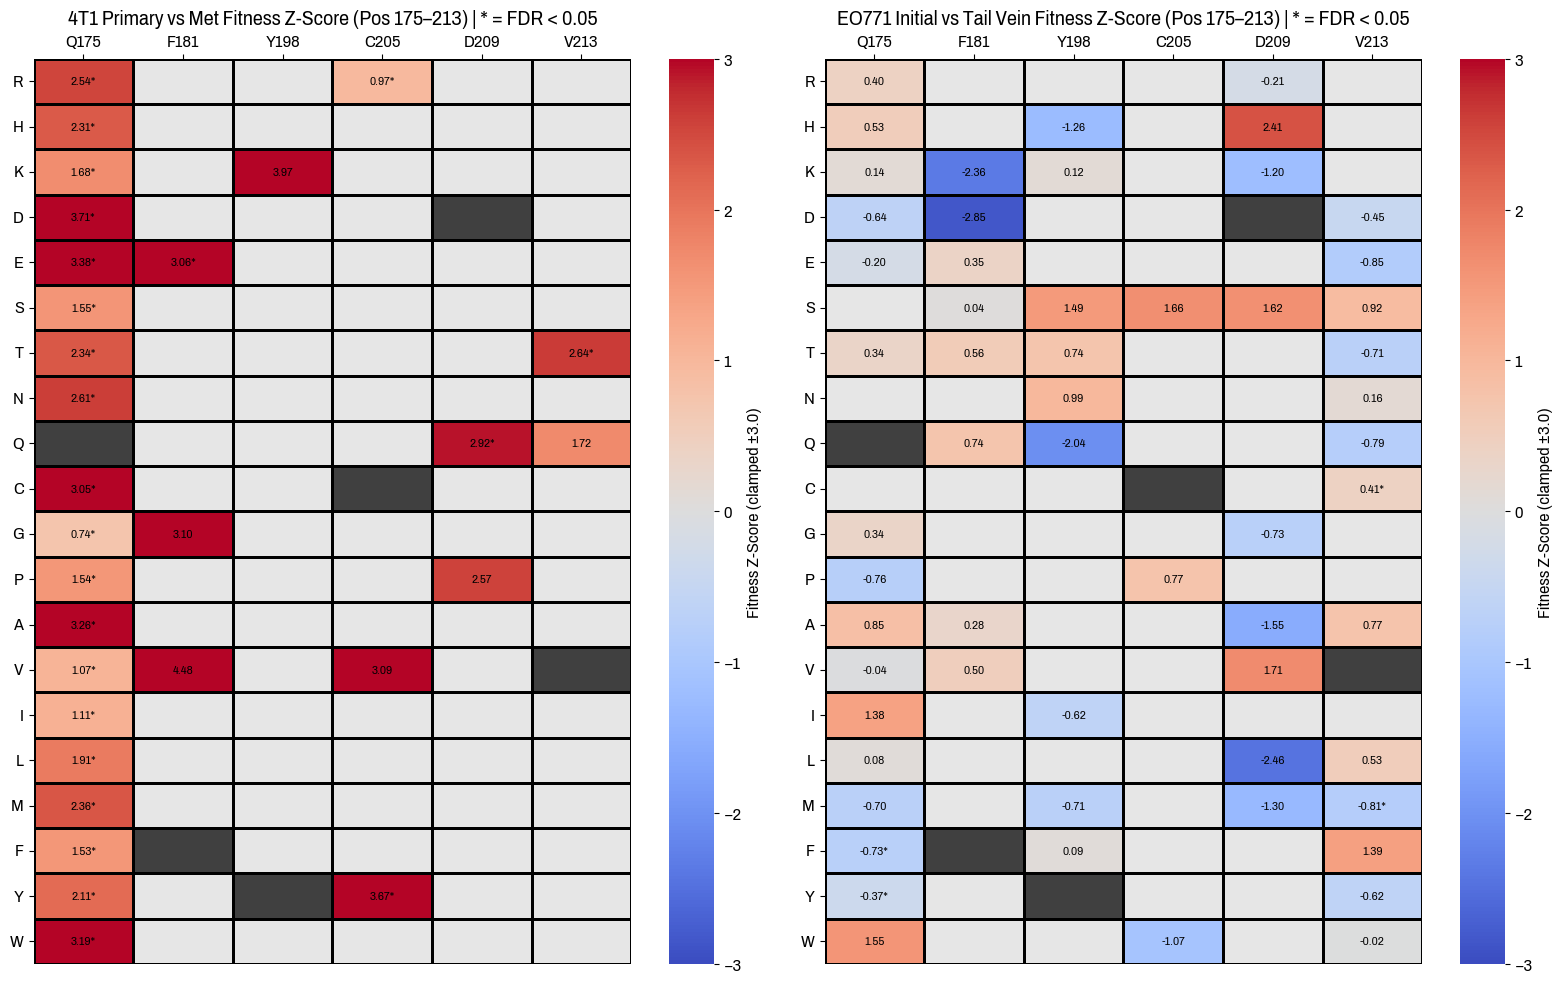

In [10]:
# Focused residue heatmaps (Z-Scored Fitness) at positions 175, 181, 198, 205, 209, 213 for 4T1 Primary vs Met and EO771 Initial vs Tail Vein
def plot_subset_fitness_heatmap(fitness_tests_df: pd.DataFrame, positions_subset: list[int], title: str, ax: plt.Axes):
    amino_acids = ["R", "H", "K", "D", "E", "S", "T", "N", "Q", "C", "G", "P", "A", "V", "I", "L", "M", "F", "Y", "W"]
    n_aas = len(amino_acids)
    n_pos = len(positions_subset)
    fitness_mat = np.full((n_aas, n_pos), np.nan)
    sig_mat = np.full((n_aas, n_pos), False)
    wt_mat = np.zeros((n_aas, n_pos))

    pos_to_col = {p: idx for idx, p in enumerate(positions_subset)}
    sub_df = fitness_tests_df[fitness_tests_df["position"].isin(positions_subset)]
    for _, row in sub_df.iterrows():
        alt = row["alt"]
        if alt not in amino_acids:
            continue
        r_idx = amino_acids.index(alt)
        c_idx = pos_to_col[int(row["position"])]
        fitness_mat[r_idx, c_idx] = row["fitness_zscore"]
        if not np.isnan(row["fdr"]) and row["fdr"] < 0.05:
            sig_mat[r_idx, c_idx] = True

    for c_idx, p in enumerate(positions_subset):
        wt_aa = mSTING[p - 1]
        if wt_aa in amino_acids:
            wt_mat[amino_acids.index(wt_aa), c_idx] = 1.0

    not_detected = np.isnan(fitness_mat)
    col_labels = [f"{mSTING[p - 1]}{p}" for p in positions_subset]

    fitness_cmap = mpl.colormaps.get_cmap("coolwarm")
    fitness_norm = mpl.colors.TwoSlopeNorm(vmin=-3.0, vmax=3.0, vcenter=0)
    grey_cmap = mpl.colors.ListedColormap([[1, 1, 1], [0.9, 0.9, 0.9]])
    grey_norm = mpl.colors.BoundaryNorm([0, 0.5, 1], 2)
    wt_cmap = mpl.colors.ListedColormap([[1, 1, 1], [0.25, 0.25, 0.25]])

    sns.heatmap(
        fitness_mat, ax=ax, cmap=fitness_cmap, norm=fitness_norm,
        yticklabels=amino_acids, xticklabels=col_labels, cbar=True,
        cbar_kws={"label": "Fitness Z-Score (clamped ±3.0)"},
        linewidths=0.8, linecolor="black", mask=not_detected,
    )
    sns.heatmap(
        not_detected.astype(float), ax=ax, cmap=grey_cmap, norm=grey_norm,
        yticklabels=amino_acids, xticklabels=col_labels, cbar=False,
        linewidths=0.8, linecolor="black", mask=~not_detected,
    )
    sns.heatmap(
        wt_mat, ax=ax, cmap=wt_cmap, norm=grey_norm,
        yticklabels=amino_acids, xticklabels=col_labels, cbar=False,
        linewidths=0.8, linecolor="black", mask=(wt_mat == 0),
    )

    for i in range(n_aas):
        for j in range(n_pos):
            val = fitness_mat[i, j]
            if not np.isnan(val):
                star = "*" if sig_mat[i, j] else ""
                ax.text(j + 0.5, i + 0.5, f"{val:.2f}{star}", ha="center", va="center", fontsize=8.5, color="black")

    ax.xaxis.tick_top()
    ax.set_yticklabels(amino_acids, rotation=0)
    ax.set_title(title, pad=25)
    return ax

fig, axes = plt.subplots(1, 2, figsize=(16, 10))
plot_subset_fitness_heatmap(stats_4t1, target_positions_int, "4T1 Primary vs Met Fitness Z-Score (Pos 175–213) | * = FDR < 0.05", axes[0])
plot_subset_fitness_heatmap(stats_eo771, target_positions_int, "EO771 Initial vs Tail Vein Fitness Z-Score (Pos 175–213) | * = FDR < 0.05", axes[1])

plt.tight_layout()
plt.savefig("figures/pro_metastatic_175_213/4T1_and_EO771_target_positions_heatmap.svg")
plt.savefig("figures/pro_metastatic_175_213/4T1_and_EO771_target_positions_heatmap.pdf")
plt.show()


C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\3062233359.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\3062233359.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([f"{mSTING[p-1]}{p}" for p in target_positions_int])
C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\3062233359.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Austin\AppData\Local\Temp\ipykernel_30780\3062233359.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoc

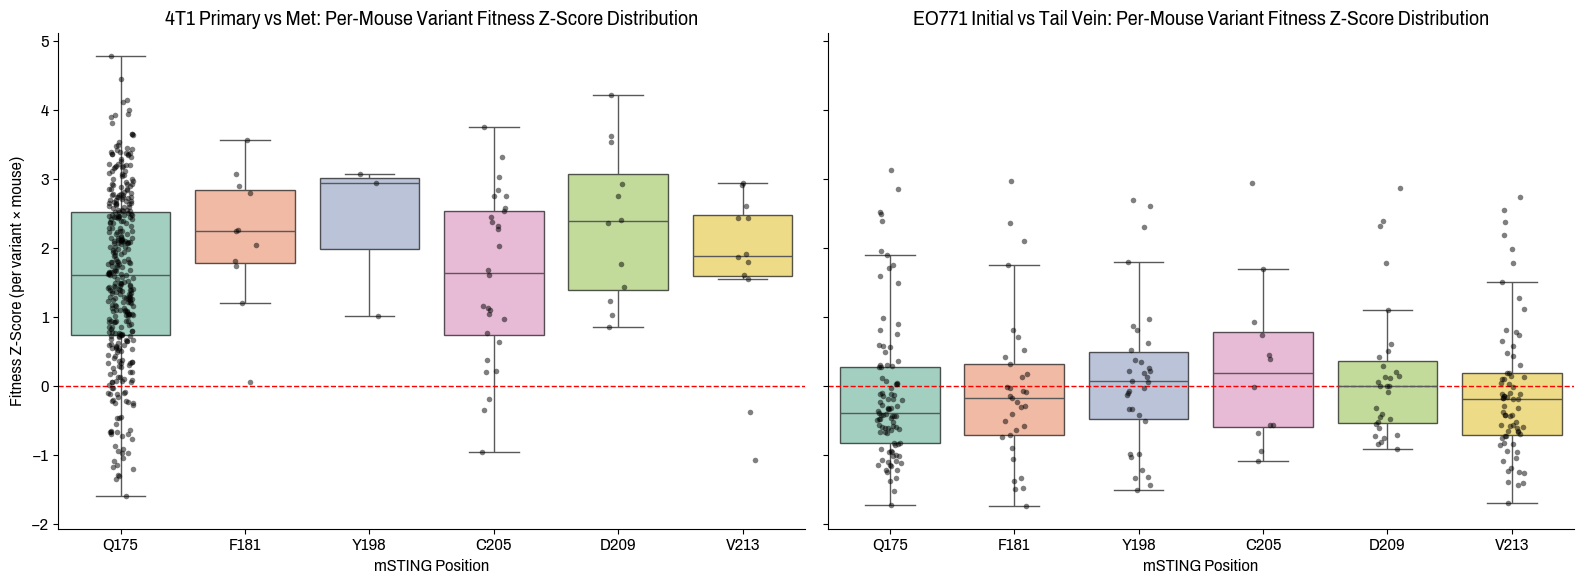

In [11]:
# Per-mouse fitness Z-score distributions across positions 175, 181, 198, 205, 209, 213 in 4T1 Primary vs Met vs EO771 Initial vs Tail Vein
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

sub_exp_4t1 = by_exp_4t1_var[(by_exp_4t1_var["position"].isin(target_positions)) & (by_exp_4t1_var["residue"] != "X")].copy()
sub_exp_eo771 = by_exp_eo771_var[(by_exp_eo771_var["position"].isin(target_positions)) & (by_exp_eo771_var["residue"] != "X")].copy()

order_pos = [str(p) for p in target_positions_int]
sns.boxplot(
    data=sub_exp_4t1,
    x="position",
    y="fitness_zscore",
    order=order_pos,
    palette=pos_palette,
    ax=axes[0],
    fliersize=0,
    boxprops=dict(alpha=0.65, edgecolor="black"),
)
sns.stripplot(
    data=sub_exp_4t1,
    x="position",
    y="fitness_zscore",
    order=order_pos,
    color="black",
    alpha=0.5,
    size=4,
    jitter=True,
    ax=axes[0],
)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_xticklabels([f"{mSTING[p-1]}{p}" for p in target_positions_int])
axes[0].set_xlabel("mSTING Position")
axes[0].set_ylabel("Fitness Z-Score (per variant × mouse)")
axes[0].set_title("4T1 Primary vs Met: Per-Mouse Variant Fitness Z-Score Distribution")
axes[0].grid(False)
sns.despine(ax=axes[0])

sns.boxplot(
    data=sub_exp_eo771,
    x="position",
    y="fitness_zscore",
    order=order_pos,
    palette=pos_palette,
    ax=axes[1],
    fliersize=0,
    boxprops=dict(alpha=0.65, edgecolor="black"),
)
sns.stripplot(
    data=sub_exp_eo771,
    x="position",
    y="fitness_zscore",
    order=order_pos,
    color="black",
    alpha=0.5,
    size=4,
    jitter=True,
    ax=axes[1],
)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xticklabels([f"{mSTING[p-1]}{p}" for p in target_positions_int])
axes[1].set_xlabel("mSTING Position")
axes[1].set_ylabel("Fitness Z-Score (per variant × mouse)")
axes[1].set_title("EO771 Initial vs Tail Vein: Per-Mouse Variant Fitness Z-Score Distribution")
axes[1].grid(False)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.savefig("figures/pro_metastatic_175_213/4T1_and_EO771_per_mouse_distributions.svg")
plt.savefig("figures/pro_metastatic_175_213/4T1_and_EO771_per_mouse_distributions.pdf")
plt.show()


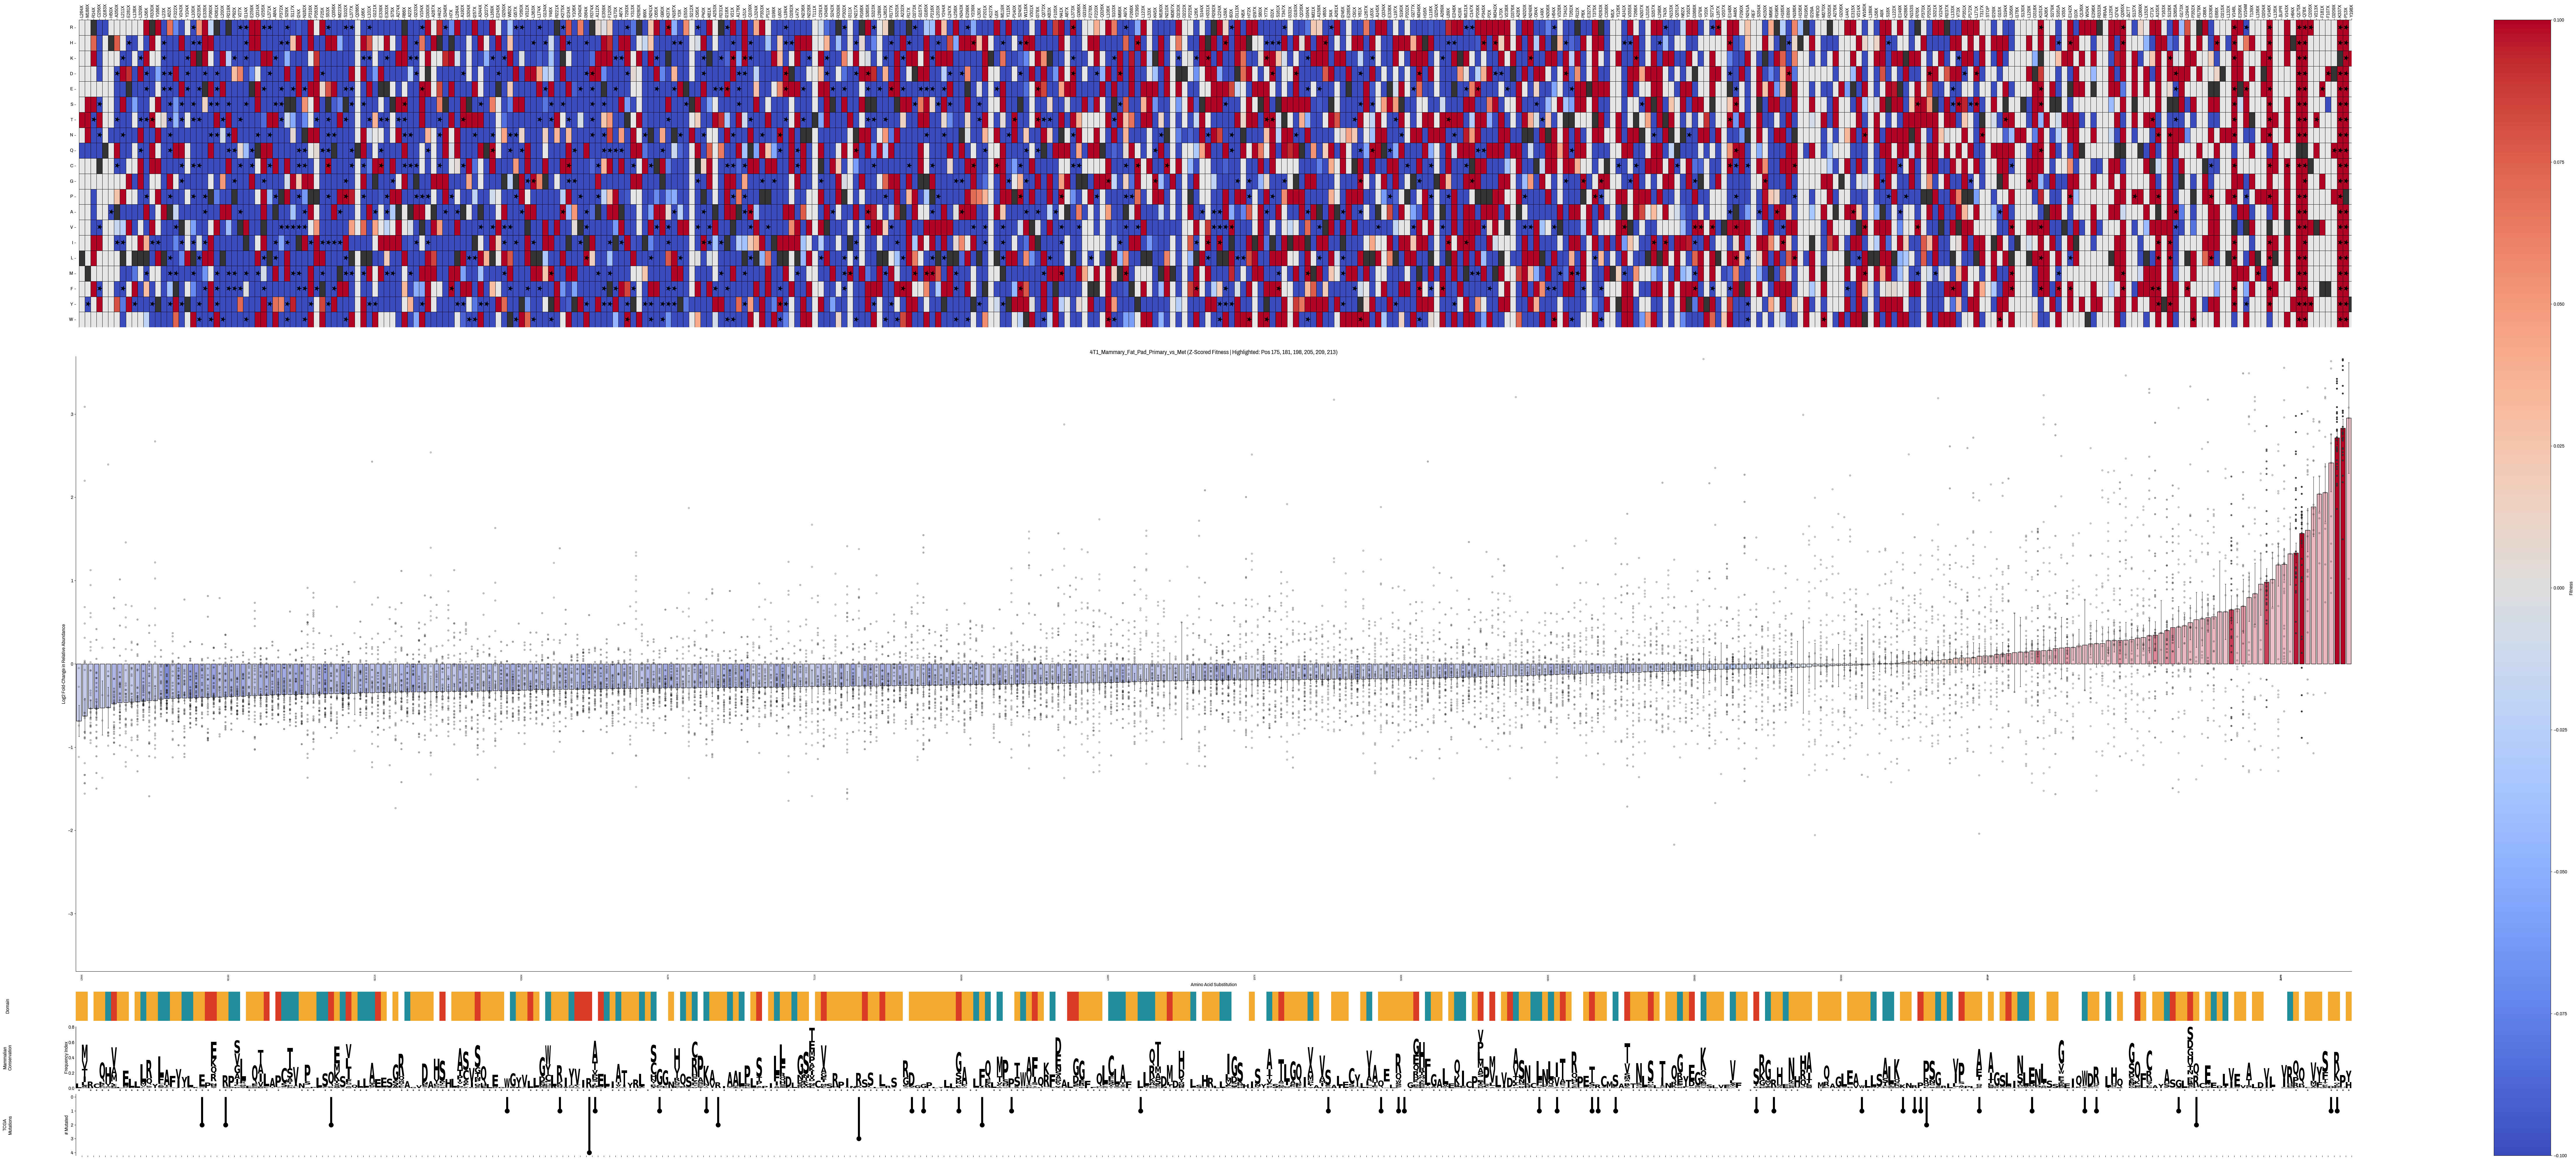

<Figure size 640x480 with 0 Axes>

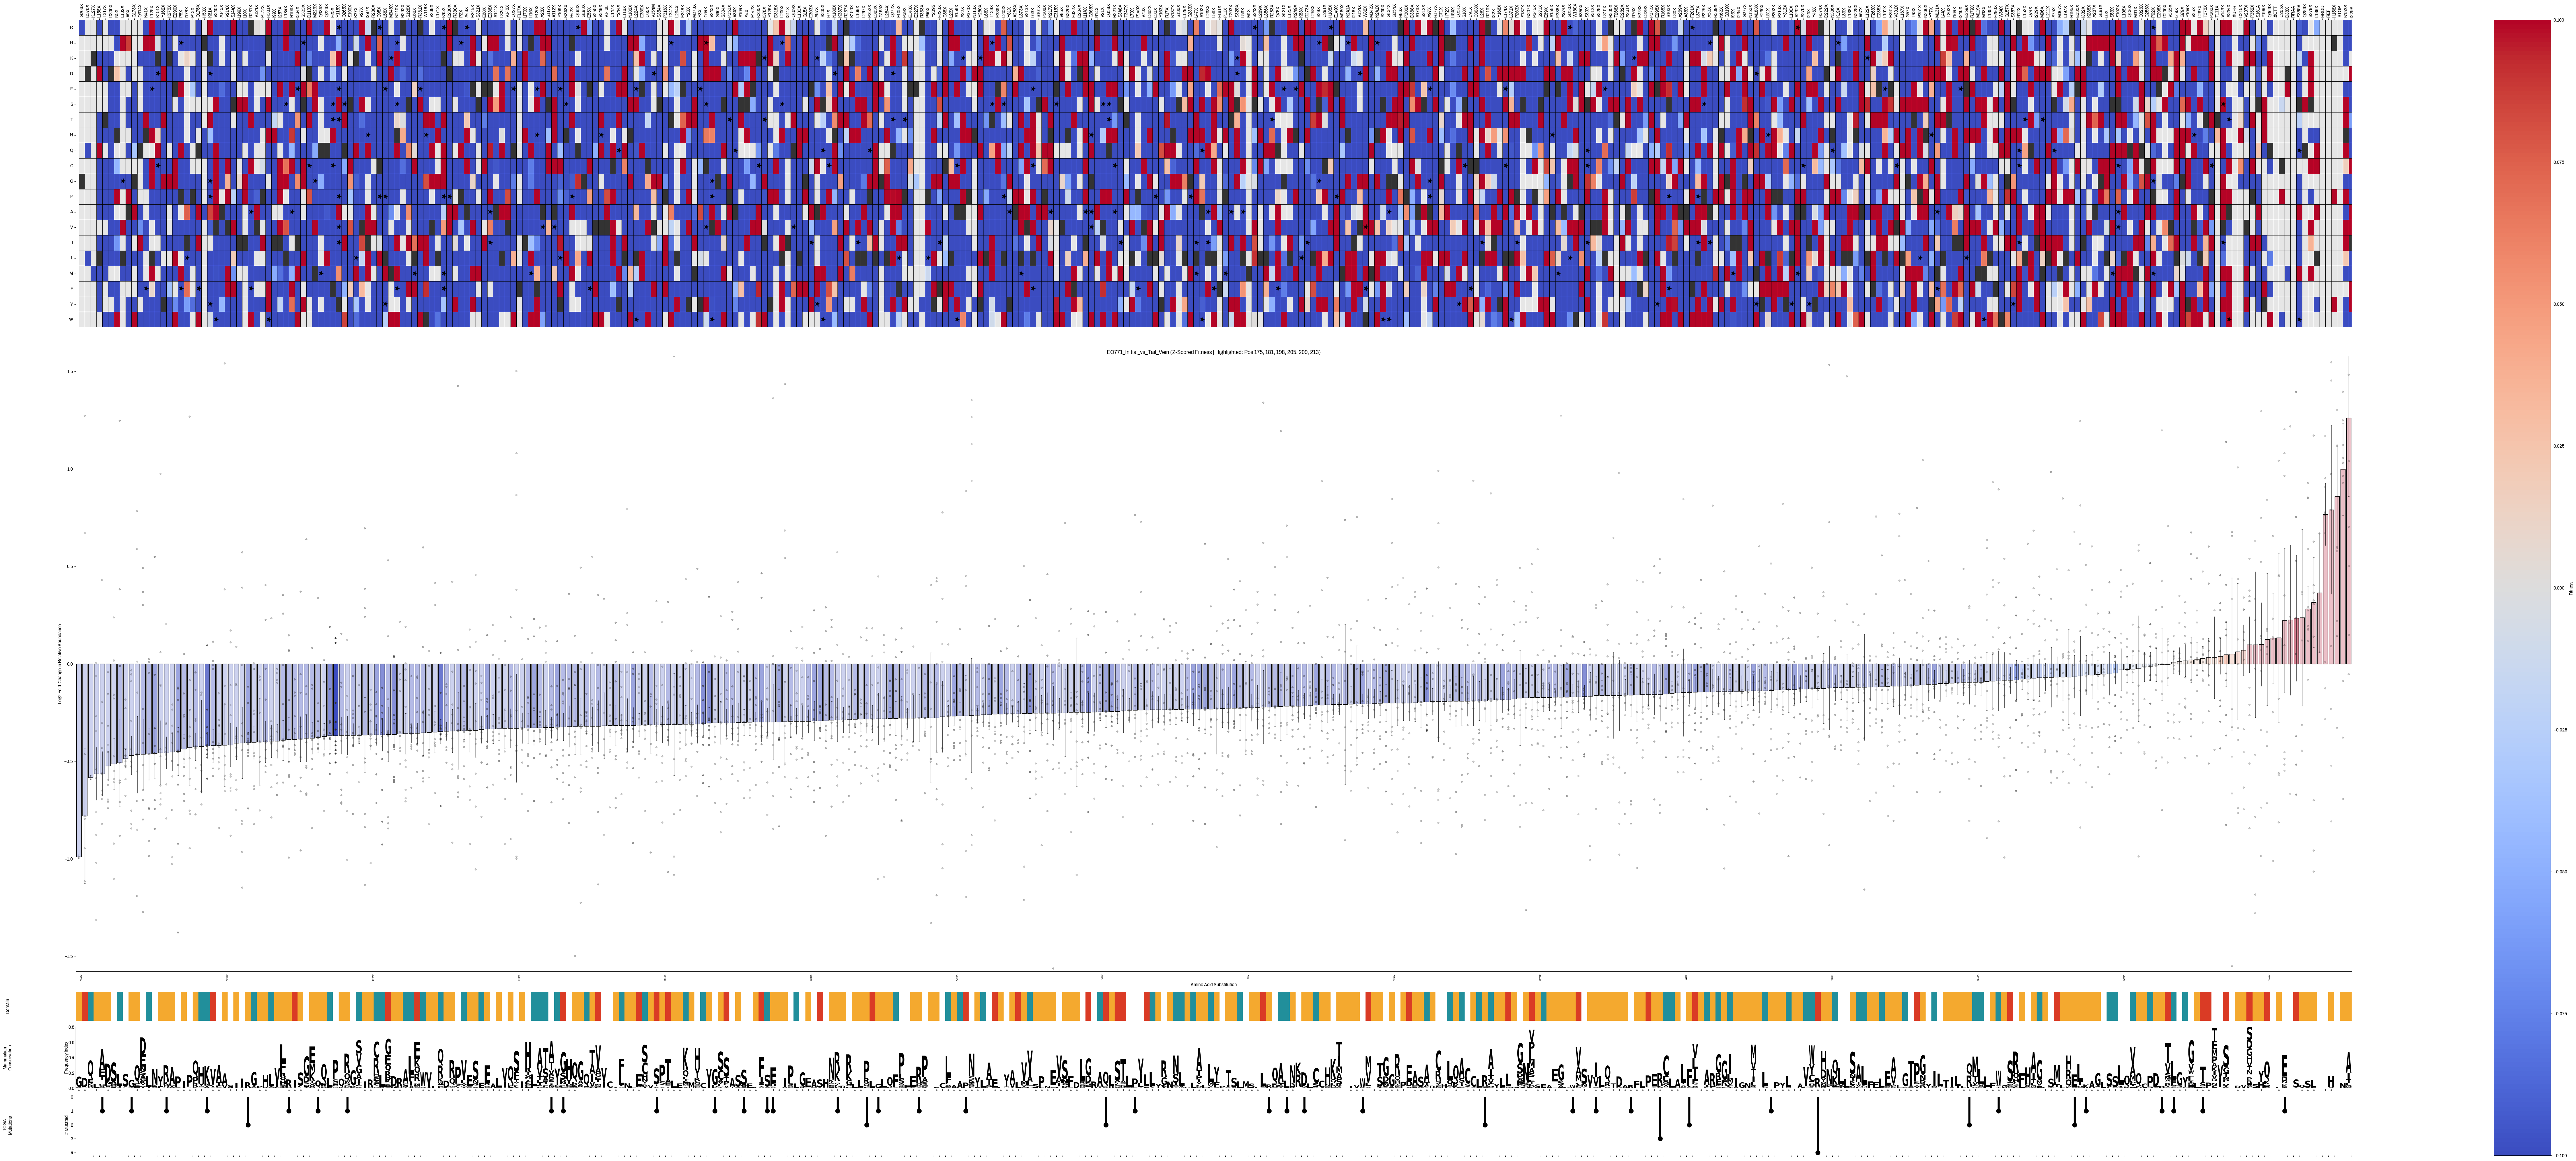

<Figure size 640x480 with 0 Axes>

In [12]:
# Full library barplots (as in analysis.ipynb) using Z-scored fitness per mouse, with target positions (175, 181, 198, 205, 209, 213) + controls highlighted
os.makedirs("figures/barplots", exist_ok=True)
highlight_target_and_controls = target_wt_labels + controls
nl = chr(10)

def zscore_experiment_fitness(df: pd.DataFrame) -> pd.DataFrame:
    """Z-score observed_fitness per mouse/experiment (matching variant_by_sample_clustered_heatmap in analysis.ipynb)."""
    df = df.copy()
    stds = df.groupby("experiment")["observed_fitness"].transform("std")
    means = df.groupby("experiment")["observed_fitness"].transform("mean")
    df["observed_fitness"] = (df["observed_fitness"] - means) / stds
    df["standard_error"] = df["standard_error"] / stds
    return df

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    make_fitness_barplot(
        total_output=zscore_experiment_fitness(experiments["4T1_Mammary_Fat_Pad_Primary_vs_Met"]),
        title="4T1_Mammary_Fat_Pad_Primary_vs_Met (Z-Scored Fitness | Highlighted: Pos 175, 181, 198, 205, 209, 213)",
        wt_sequence=mSTING,
        color_points=False,
        color_by_residue=False,
        symmetrical_y_axis=True,
        weighted=False,
        highlighted_positions=highlight_target_and_controls,
        intermediate_output_file="figures/pro_metastatic_175_213/4T1_MFP_Primary_vs_Met_Barplot.xlsx",
        tracks=[
            ("Domain", domain2color),
            ("Mammalian" + nl + "Conservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
            ("TCGA" + nl + "Mutations", make_lollipop),
        ],
    )
    plt.savefig("figures/pro_metastatic_175_213/4T1_MFP_Primary_vs_Met_Highlighted_Barplot.svg")
    plt.savefig("figures/pro_metastatic_175_213/4T1_MFP_Primary_vs_Met_Highlighted_Barplot.pdf")
    plt.show()
    plt.clf()

    make_fitness_barplot(
        total_output=zscore_experiment_fitness(experiments["EO771_Initial_vs_Tail_Vein"]),
        title="EO771_Initial_vs_Tail_Vein (Z-Scored Fitness | Highlighted: Pos 175, 181, 198, 205, 209, 213)",
        wt_sequence=mSTING,
        color_points=False,
        color_by_residue=False,
        symmetrical_y_axis=True,
        weighted=False,
        highlighted_positions=highlight_target_and_controls,
        intermediate_output_file="figures/pro_metastatic_175_213/EO771_Tail_Vein_Barplot.xlsx",
        tracks=[
            ("Domain", domain2color),
            ("Mammalian" + nl + "Conservation", functools.partial(make_logo, annotate_positions=conservation_df[conservation_df['Conserved'] == 1]['mouse pos int'].astype(str).values.tolist() + ['REF'])),
            ("TCGA" + nl + "Mutations", make_lollipop),
        ],
    )
    plt.savefig("figures/pro_metastatic_175_213/EO771_Tail_Vein_Highlighted_Barplot.svg")
    plt.savefig("figures/pro_metastatic_175_213/EO771_Tail_Vein_Highlighted_Barplot.pdf")
    plt.show()
    plt.clf()
